# NumCompute-Stream demo

This notebook trains a decision tree on data that arrives in chunks instead of all at once. It reads a CSV file with io.load_csv, splits it into chunks of 100 rows with io.iter_chunks, and passes each chunk to a pipeline's partial_fit. The metrics are logged after every chunk and plotted at the end with the functions in visualise.py.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from numcompute_stream.io import load_csv, iter_chunks
from numcompute_stream.pipeline import Pipeline
from numcompute_stream.preprocessing import Imputer, StandardScaler
from numcompute_stream.tree import DecisionTreeClassifier
from numcompute_stream.metrics import Accuracy, F1, StreamingAUC
from numcompute_stream.stream import StreamTrainer
from numcompute_stream.visualise import (plot_metric_over_time, compare_models,
                                         plot_predictions_vs_ground_truth)

## Loading the data

The file data/sensor_stream.csv holds 12,000 made-up readings from four sensors on a machine, each labelled ok or fault. About 3% of the readings are blank and 5% of the labels are deliberately wrong, so the model has to cope with missing values and noise.

Halfway through the file, the rule that decides between ok and fault changes. In the first half a reading is a fault when sensors 1 and 2 are far from their usual values. In the second half it depends on sensors 1 and 3 instead. This is called concept drift, and a model that learns from a stream has to be able to recover from it. With 100 rows per chunk, the change happens at chunk 60. The file is generated by data/make_sensor_stream.py.

The status column is text, so the file is loaded with dtype=object and the columns are converted to numbers and strings afterwards.

In [2]:
data = load_csv("data/sensor_stream.csv", skip_header=1, dtype=object)  # text label column
X = data[:, :4].astype(np.float64)
y = data[:, 4].astype(str)

print("X:", X.shape, f"- {np.isnan(X).mean():.1%} missing")
labels, counts = np.unique(y, return_counts=True)
print("labels:", dict(zip(labels.tolist(), counts.tolist())))

X: (12000, 4) - 3.0% missing
labels: {'fault': 6613, 'ok': 5387}


## Training on the stream

The pipeline has three steps. Imputer fills in missing readings with the running mean of each sensor, StandardScaler rescales each sensor using its running mean and standard deviation, and DecisionTreeClassifier makes the prediction. The first two steps update their statistics with every chunk. A decision tree can't be updated a few rows at a time, so the tree keeps incoming rows in a buffer and builds a new tree once the buffer holds buffer_size rows. It can't predict anything until its first tree is built.

I run two copies of the pipeline that only differ in buffer size (300 and 2000 rows) to see how that setting changes the results.

Each chunk is used for testing first and training second. score_chunk predicts the chunk with the current model and records the accuracy, then fit_chunk calls pipeline.partial_fit on the same chunk. The model hasn't seen the chunk when it is scored, so the accuracy is measured on new data, the same as it would be if the model were running live.

The table prints every 10 chunks. "rolling acc" is the accuracy over the last 10 chunks, AUC covers every chunk so far, and memory is the size of the arrays the pipeline holds, which is mostly the tree's buffer.

In [3]:
def make_trainer(buffer_size):
    pipe = Pipeline([("impute", Imputer(strategy="mean")),
                     ("scale", StandardScaler()),
                     ("tree", DecisionTreeClassifier(max_depth=6, buffer_size=buffer_size))])
    return StreamTrainer(pipe, metrics={"rolling_accuracy": Accuracy(window=10),
                                        "auc": StreamingAUC(pos_label="fault")})

small, large = make_trainer(300), make_trainer(2000)

print("chunk  seen   | buffer 300: rolling acc  AUC   memory | buffer 2000: rolling acc")
for i, (X_chunk, y_chunk) in enumerate(iter_chunks(X, y, chunk_size=100), start=1):
    for trainer in (small, large):
        trainer.score_chunk(X_chunk, y_chunk)    # 1. test on the new chunk
        trainer.fit_chunk(X_chunk, y_chunk)      # 2. then train on it (partial_fit)
    if i % 10 == 0:
        late = large.history("rolling_accuracy")[-1]           # NaN until its first tree
        print(f"{i:5d} {small.history('n_samples_seen')[-1]:6.0f}   |"
              f"{small.history('rolling_accuracy')[-1]:20.3f} {small.history('auc')[-1]:6.3f}"
              f" {small.history('model_bytes')[-1] / 1024:5.1f} kB |"
              + ("buffering".rjust(24) if np.isnan(late) else f"{late:24.3f}"))

chunk  seen   | buffer 300: rolling acc  AUC   memory | buffer 2000: rolling acc
   10   1000   |               0.843  0.837   7.7 kB |               buffering
   20   2000   |               0.830  0.830  13.2 kB |               buffering
   30   3000   |               0.838  0.828   2.2 kB |                   0.884
   40   4000   |               0.856  0.839   7.7 kB |                   0.890


   50   5000   |               0.829  0.834  12.1 kB |                   0.873
   60   6000   |               0.832  0.831   2.4 kB |                   0.887
   70   7000   |               0.730  0.818   7.6 kB |                   0.531
   80   8000   |               0.830  0.822  13.2 kB |                   0.526


   90   9000   |               0.821  0.825   3.0 kB |                   0.914
  100  10000   |               0.845  0.828   8.4 kB |                   0.900
  110  11000   |               0.830  0.829  13.5 kB |                   0.898
  120  12000   |               0.828  0.829   3.0 kB |                   0.898


## Plotting the logs

StreamTrainer keeps one value per chunk for every metric, and history(name) returns them as an array, which is what plot_metric_over_time takes. These four plots are for the buffer 300 pipeline.

The rolling accuracy drops sharply at chunk 60 (the dashed line) when the rule changes, and recovers about ten chunks later once the tree has been rebuilt on rows from after the change. The cumulative AUC moves much less at the same point because it averages over every chunk so far, which is why the rolling accuracy is the better one for spotting drift.

The bottom two plots show the buffer working. Memory climbs as rows are added and drops back when the tree is rebuilt and the buffer is cleared. Each rebuild also shows up as a spike in the time taken to process that chunk.

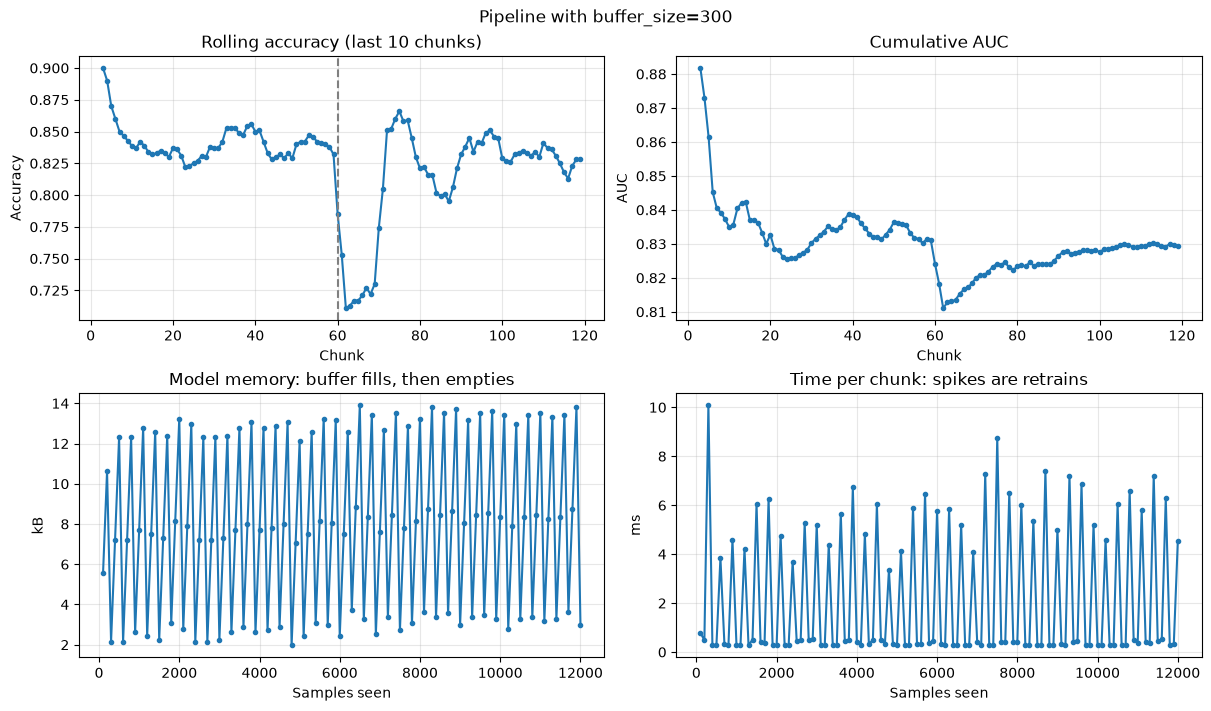

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
seen = small.history("n_samples_seen")
plot_metric_over_time(small.history("rolling_accuracy"), "Rolling accuracy (last 10 chunks)",
                      "Accuracy", ax=axes[0, 0])
plot_metric_over_time(small.history("auc"), "Cumulative AUC", "AUC", ax=axes[0, 1])
plot_metric_over_time(small.history("model_bytes") / 1024, "Model memory: buffer fills, then empties",
                      "kB", x=seen, xlabel="Samples seen", ax=axes[1, 0])
plot_metric_over_time(small.history("fit_time") * 1000, "Time per chunk: spikes are retrains",
                      "ms", x=seen, xlabel="Samples seen", ax=axes[1, 1])
axes[0, 0].axvline(60, color="grey", linestyle="--")
fig.suptitle("Pipeline with buffer_size=300");

## Comparing buffer sizes

compare_models puts the rolling accuracy of both pipelines on one plot. The plot is also saved to compare_buffer_size.png using the save_path option.

The buffer 2000 pipeline has no tree for the first 20 chunks, so its line starts later. Once it has one, it is more accurate than the buffer 300 pipeline (about 0.88 compared with 0.83) because each tree is trained on more rows. After the drift this flips. Its tree was built at chunk 60 from old data, and the first rebuild that only uses new data happens at chunk 80, so for about 20 chunks its accuracy is close to 0.5, which is no better than guessing. The smaller buffer is rebuilt every three chunks, so it recovers much sooner.

So choosing buffer_size means choosing between accuracy while the data is stable and how quickly the model adapts when it changes.

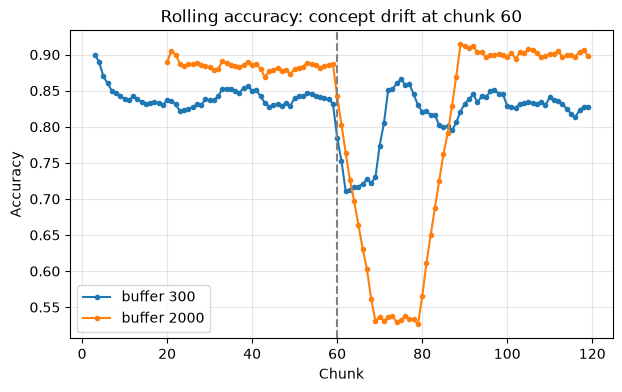

In [5]:
ax = compare_models(small.history("rolling_accuracy"), large.history("rolling_accuracy"),
                    labels=("buffer 300", "buffer 2000"),
                    title="Rolling accuracy: concept drift at chunk 60", ylabel="Accuracy",
                    save_path="compare_buffer_size.png")
ax.axvline(60, color="grey", linestyle="--");

## Predictions on the last chunk

StreamTrainer keeps the true labels and predictions from the most recent chunk it scored. The confusion matrix shows where the buffer 300 pipeline went wrong on that chunk. Most of its mistakes are faults that it labelled as ok, which on a real machine would be the more costly kind of mistake.

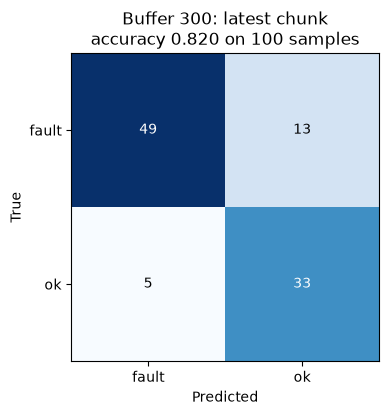

In [6]:
plot_predictions_vs_ground_truth(small.last_y_true_, small.last_y_pred_,
                                 title="Buffer 300: latest chunk");

## Summary

The pipeline learned from the stream one chunk at a time. Apart from the tree's buffer, it only stores a few running statistics per sensor, so the memory it uses doesn't grow with the length of the stream. The buffer size had the biggest effect on the results. benchmark/results.md tries five buffer sizes on three versions of this stream and also records how long each rebuild takes.